# hw2: Решающие деревья

*Спасибо великому курсу великого Евгения Соколова*

### О задании

Задание состоит из двух разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево и сравните его со стандартное имплементацией из sklearn. Вы также протестируете деревья на более сложных датасетах и сравните различные подходы к кодированию категориальных признаков.

Все данные, на которых будут обучаться модели, вы можете найти на диске.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов. Неэффективная и/или неоригинальная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Заполненный ноутбук ```hw2-trees.ipynb``` и модуль с реализованными функциями и классами ```hw2code.py``` необходимо загрузить на свой Github. Затем нужно оставить комментарий в Google-таблице с оценками в столбце <<hw2>> в строке со своей фамилией о том, что вы выполнили работу с указанием ника на Kaggle. 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import ListedColormap
from sklearn.metrics import accuracy_score, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

from hw2code import DecisionTree, find_best_split

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path("datasets")

# 1. Решающие деревья. Визуализация.

В этой части мы рассмотрим два простых двумерных датасета сделанных с помощью `make_moons`, `make_circles` и посмотрим как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [2]:
from sklearn.datasets import make_moons, make_circles, make_classification
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0)
]

In [3]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

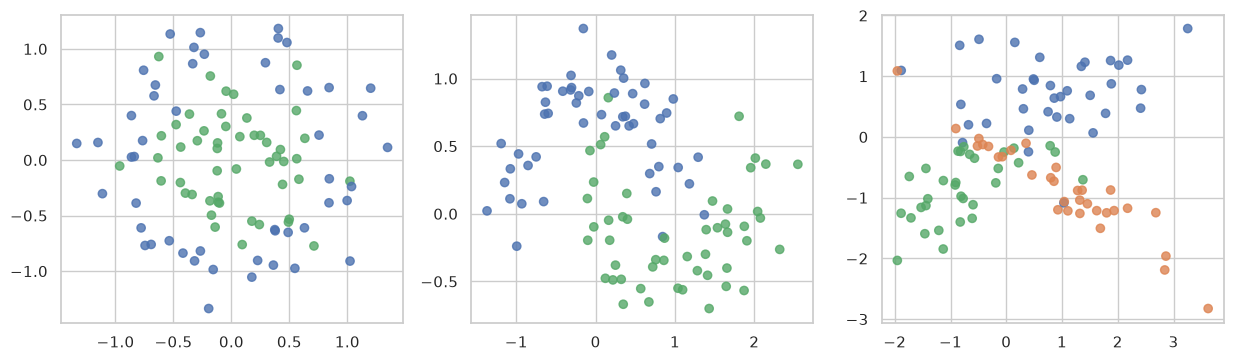

In [4]:
plt.figure(figsize=(15, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap=cmap, alpha=.8)

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

In [5]:
def plot_surface(clf, X, y):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=0.7,
                edgecolors=np.array(palette)[y], linewidths=2)

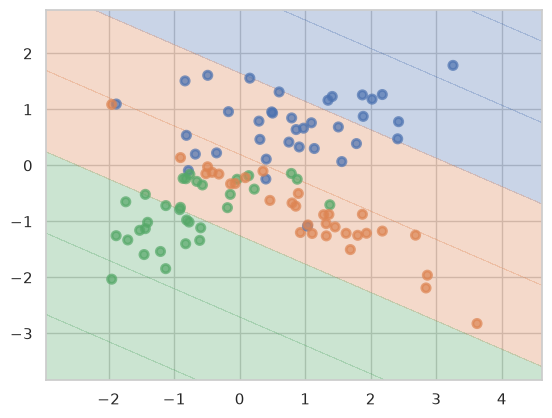

In [6]:
# Пример:
from sklearn.linear_model import LinearRegression
X, y = datasets[2]
lr  = LinearRegression().fit(X, y)
plot_surface(lr, X, y)

,Train accuracy,Test accuracy
Датасет,,
Circles,1.0,0.700
Moons,1.0,0.933
Три класса,1.0,0.667


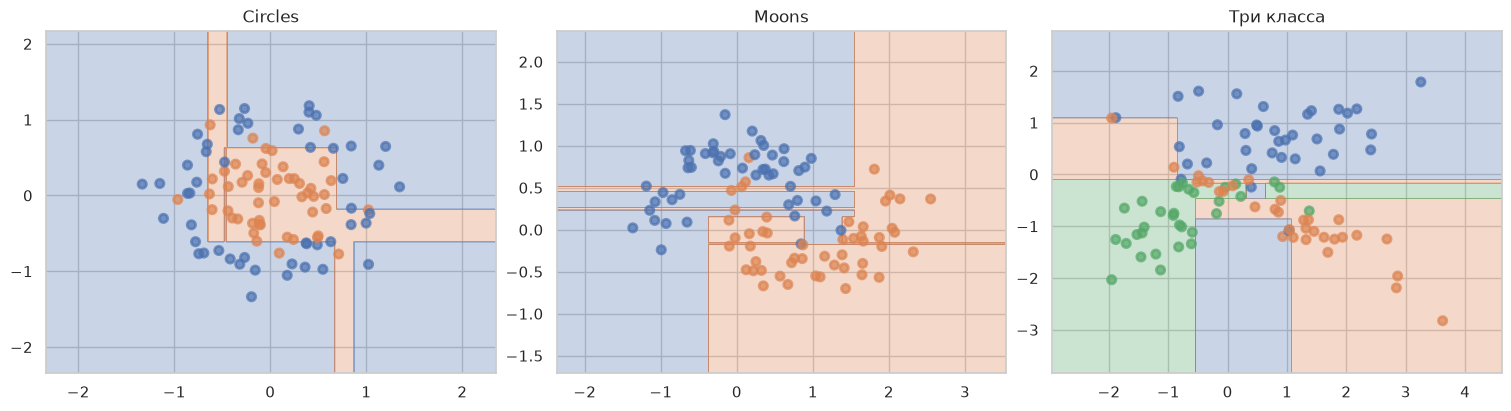

In [7]:
dataset_names = ["Circles", "Moons", "Три класса"]
splits = {
    name: train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
    for name, (X, y) in zip(dataset_names, datasets)
}

rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, name, (X, y) in zip(axes, dataset_names, datasets):
    X_train, X_test, y_train, y_test = splits[name]
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append({
        "Датасет": name,
        "Train accuracy": clf.score(X_train, y_train),
        "Test accuracy": clf.score(X_test, y_test),
    })
    plt.sca(ax)
    plot_surface(clf, X, y)
    ax.set_title(name)

default_scores = pd.DataFrame(rows).set_index("Датасет")
display(default_scores.round(3))
plt.show()

__Ответ:__

На обучении accuracy равна `1,000` у всех трёх деревьев. На тесте она
составляет `0,700` для Circles, `0,933` для Moons и `0,667` для набора
с тремя классами. Разрыв заметнее всего у Circles и трёхклассового набора
(30,0 и 33,3 п. п.). На их графиках видны небольшие прямоугольные области,
появившиеся вокруг отдельных обучающих точек. У Moons разрыв составляет
6,7 п. п., поэтому на этом разбиении переобучение выражено слабее. В каждом
тесте всего 30 точек, поэтому один промах меняет accuracy на 3,3 п. п.

__Задание 2. (1.5 балла)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

Train error  Test error
Датасет    Ограничение                                   
Circles    max_depth = 2                0.186       0.367
           max_depth = 5                0.014       0.300
           min_samples_leaf = 5         0.057       0.167
           min_samples_leaf = 10        0.114       0.300
Moons      max_depth = 2                0.071       0.067
           max_depth = 5                0.029       0.067
           min_samples_leaf = 5         0.100       0.200
           min_samples_leaf = 10        0.143       0.233
Три класса max_depth = 2                0.100       0.167
           max_depth = 5                0.014       0.333
           min_samples_leaf = 5         0.114       0.167
           min_samples_leaf = 10        0.114       0.167

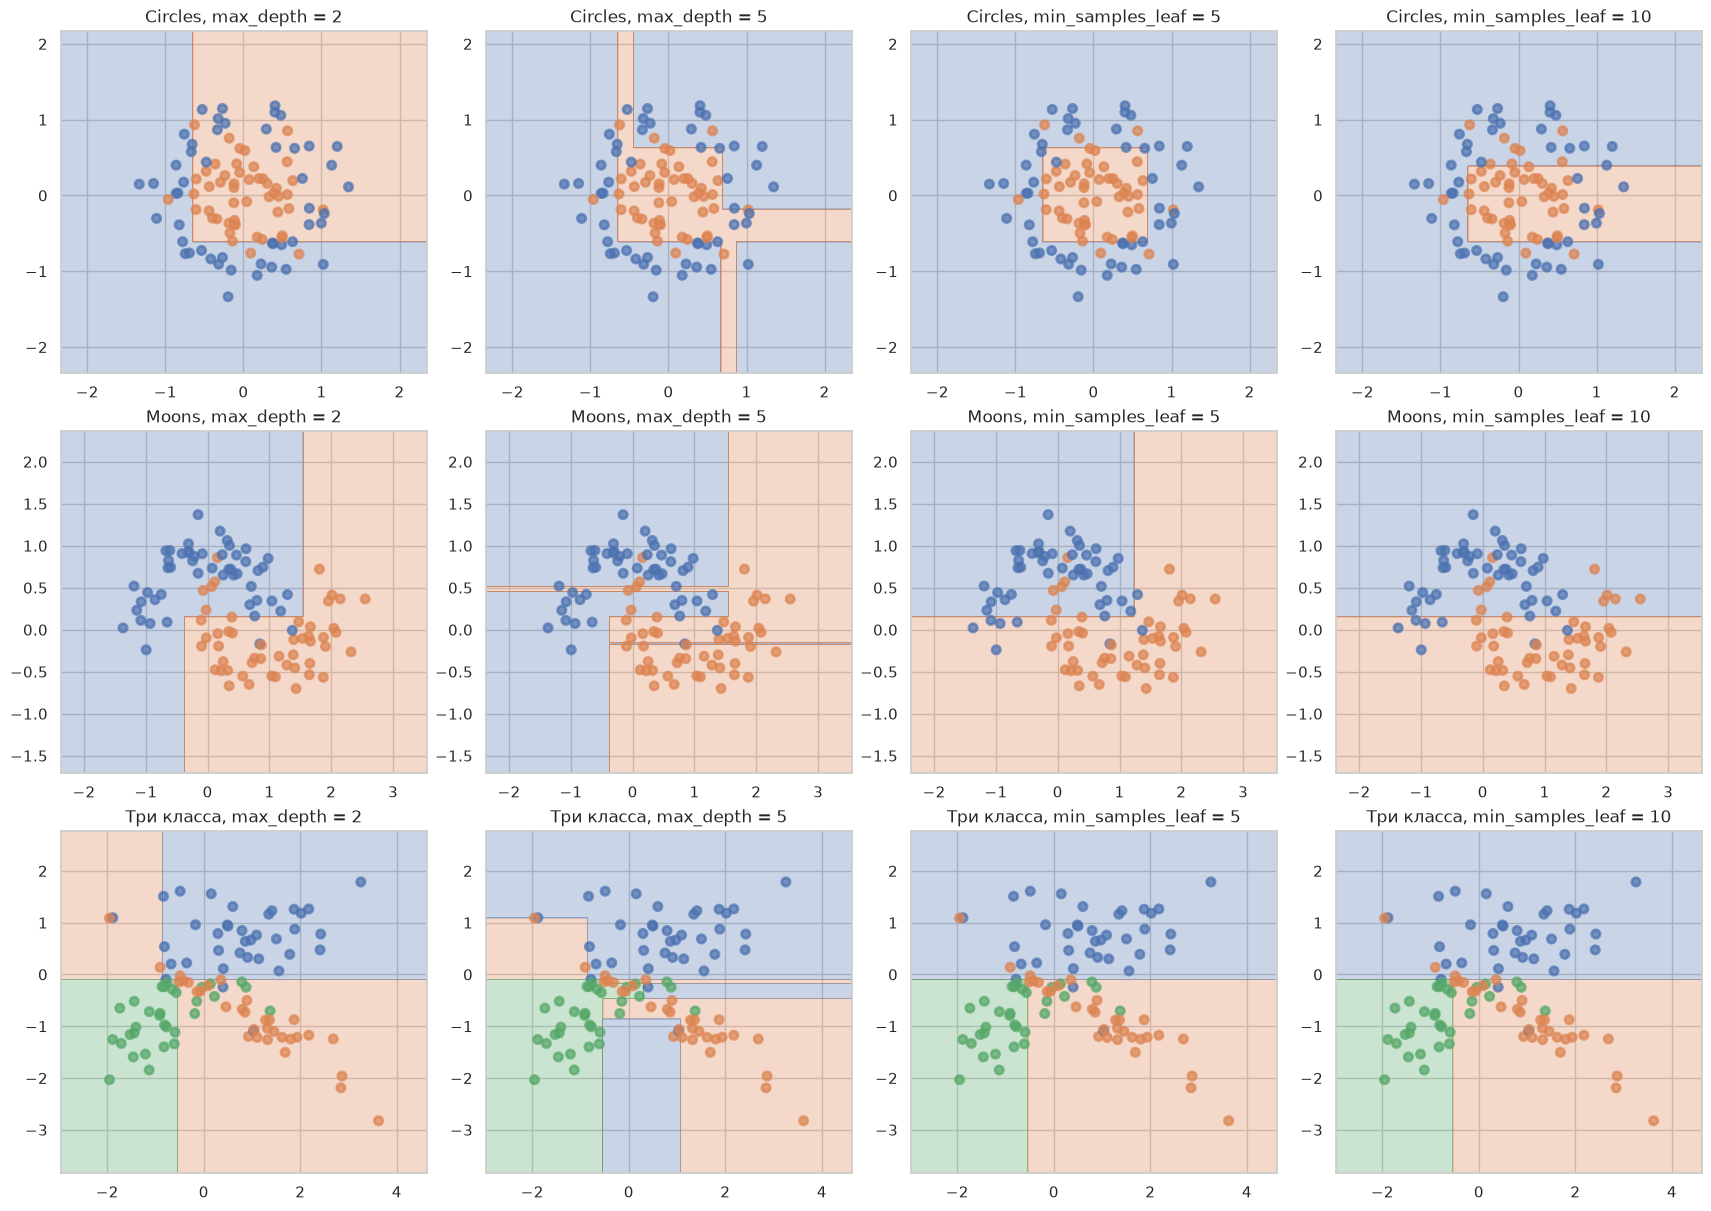

In [8]:
configurations = [
    ("max_depth = 2", {"max_depth": 2}),
    ("max_depth = 5", {"max_depth": 5}),
    ("min_samples_leaf = 5", {"min_samples_leaf": 5}),
    ("min_samples_leaf = 10", {"min_samples_leaf": 10}),
]

rows = []
fig, axes = plt.subplots(3, 4, figsize=(17, 12), layout="constrained")
for i, (name, (X, y)) in enumerate(zip(dataset_names, datasets)):
    X_train, X_test, y_train, y_test = splits[name]
    for j, (title, params) in enumerate(configurations):
        clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **params)
        clf.fit(X_train, y_train)
        rows.append({
            "Датасет": name,
            "Ограничение": title,
            "Train error": 1 - clf.score(X_train, y_train),
            "Test error": 1 - clf.score(X_test, y_test),
        })
        ax = axes[i, j]
        plt.sca(ax)
        plot_surface(clf, X, y)
        ax.set_title(f"{name}, {title}")

regularization_scores = pd.DataFrame(rows).set_index(["Датасет", "Ограничение"])
display(regularization_scores.round(3))
plt.show()

__Ответ:__

- **Circles.** При `min_samples_leaf=5` тестовая ошибка упала с `0,300`
  до `0,167`, хотя обучающая выросла с `0,000` до `0,057`. Мелкие области
  исчезли, а дерево сохранило достаточно разбиений, чтобы приблизить круг.
  При `max_depth=2` граница слишком грубая, и тестовая ошибка выросла до `0,367`.
- **Moons.** При `max_depth=2` граница стала проще, а тестовая ошибка
  осталась `0,067`. Увеличение минимального размера листа до 5 и 10
  подняло ошибку до `0,200` и `0,233`. На этом разбиении крупные листья
  склеили области, которые стоило разделить.
- **Три класса.** При `max_depth=2` или `min_samples_leaf` в 5 либо 10
  объектов тестовая ошибка снижается с `0,333` до `0,167`. При `max_depth=5`
  она остаётся `0,333`, хотя обучающая ошибка всего `0,014`. На графиках
  более сильные ограничения убирают мелкие области между группами.

Ограничение глубины уменьшает число последовательных разбиений, а
ограничение размера листа мешает выделять небольшие группы точек.
Подходящая сила ограничения зависит от сложности границы и от того,
какие пограничные точки попали в обучающую выборку.

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw2code.py

Реализация находится в `hw2code.py`. После сортировки признака накопительная
сумма меток даёт число объектов класса `1` в левой ветви для любого порога.
Число объектов класса `1` в правой ветви получается вычитанием из общего числа.

__Задание 4. (0.5 балла)__

Загрузите таблицу students.csv (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

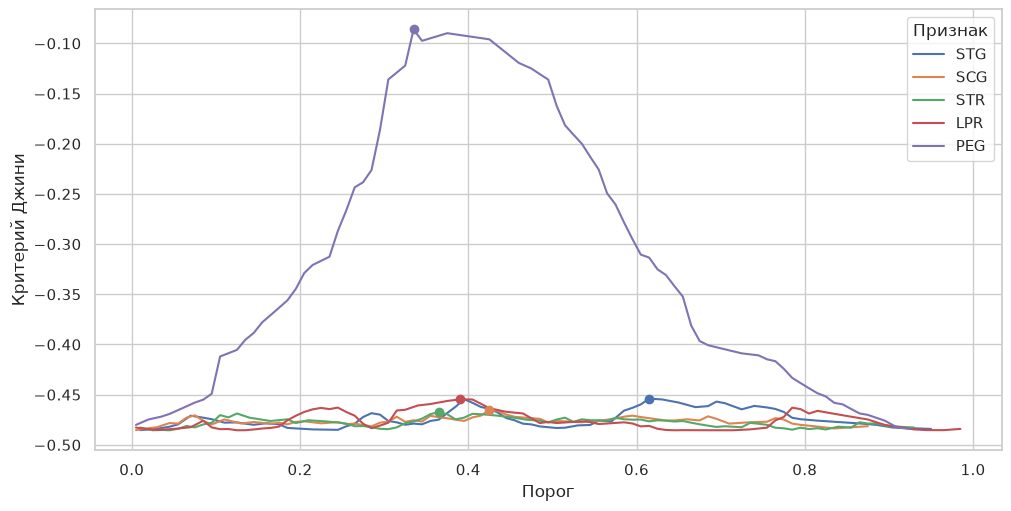

,Лучший порог,Критерий Джини
Признак,,
PEG,0.335,-0.0861
STG,0.615,-0.4540
LPR,0.390,-0.4547
SCG,0.425,-0.4650
STR,0.365,-0.4673


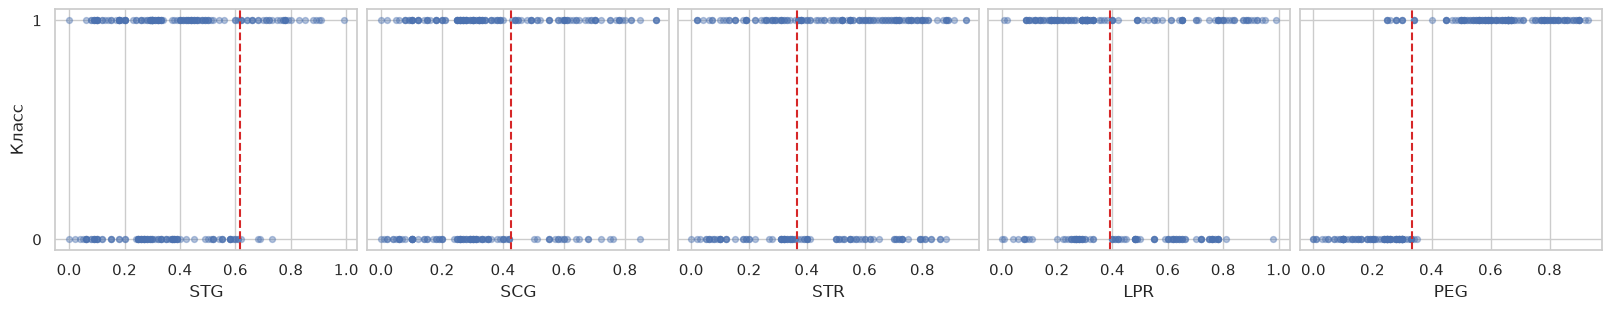

In [9]:
students = pd.read_csv(DATA_DIR / "students.csv")
X_students = students.iloc[:, :5]
y_students = students.iloc[:, -1].to_numpy()

rows = []
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for feature in X_students:
    values = X_students[feature].to_numpy()
    thresholds, ginis, best_threshold, best_gini = find_best_split(values, y_students)
    line, = ax.plot(thresholds, ginis, label=feature)
    ax.scatter(best_threshold, best_gini, color=line.get_color(), zorder=3)
    rows.append({"Признак": feature, "Лучший порог": best_threshold, "Критерий Джини": best_gini})
ax.set(xlabel="Порог", ylabel="Критерий Джини")
ax.legend(title="Признак")
plt.show()

student_splits = pd.DataFrame(rows).set_index("Признак").sort_values("Критерий Джини", ascending=False)
display(student_splits.round(4))

fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True, layout="constrained")
for ax, feature in zip(axes, X_students):
    ax.scatter(X_students[feature], y_students, alpha=0.4, s=18)
    ax.axvline(student_splits.loc[feature, "Лучший порог"], color="tab:red", linestyle="--")
    ax.set(xlabel=feature, yticks=[0, 1])
axes[0].set_ylabel("Класс")
plt.show()

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:**

Корневое разбиение следует сделать по `PEG` с порогом `0,335`.
Его значение критерия `−0,0861` — максимум среди пяти признаков.
На scatter-графике это видно по смене преобладающего класса. Слева
от порога 105 из 115 объектов относятся к классу `0`, справа
141 из 143 относятся к классу `1`.

У хорошего признака кривая поднимается близко к нулю в области порогов,
где обе ветви почти однородны. Пик бывает широким, если несколько порогов
отделяют классы почти одинаково хорошо. У остальных признаков классы
перекрываются, поэтому даже максимумы находятся между `−0,4540` и `−0,4673`.

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw2code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в лекции. Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

Исправлены проверка однородности узла, перебор признаков с индекса `0`,
пропуск константных признаков и индексация целевых меток правого потомка.
В листе хранится одна метка класса. При обработке категориального признака
дерево сортирует категории по доле класса `1` среди объектов текущего узла,
применяет к рангам поиск числового порога и сохраняет множество категорий
левой ветви. При предсказании категория вне этого множества идёт вправо.

__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [10]:
def encode_columns(frame):
    return np.column_stack([LabelEncoder().fit_transform(frame[column]) for column in frame])


def tree_depth(node):
    if node["type"] == "terminal":
        return 0
    return 1 + max(tree_depth(node["left_child"]), tree_depth(node["right_child"]))


mushrooms = pd.read_csv(DATA_DIR / "agaricus-lepiota.data", header=None)
mushrooms_encoded = encode_columns(mushrooms)
X_mushrooms, y_mushrooms = mushrooms_encoded[:, 1:], mushrooms_encoded[:, 0]

X_train, X_test, y_train, y_test = train_test_split(
    X_mushrooms, y_mushrooms, test_size=0.5, stratify=y_mushrooms, random_state=RANDOM_STATE,
)
mushrooms_tree = DecisionTree(["categorical"] * X_mushrooms.shape[1]).fit(X_train, y_train)
mushrooms_accuracy = accuracy_score(y_test, mushrooms_tree.predict(X_test))
print(f"Test accuracy: {mushrooms_accuracy:.4f}")
print(f"Глубина дерева: {tree_depth(mushrooms_tree._tree)}")

Test accuracy: 1.0000
Глубина дерева: 7


__Задание 8. (бонус, 1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующий пункт).

,Лучшее значение в сетке,CV accuracy
Параметр,,
max_depth,12,0.9426
min_samples_split,2,0.9426
min_samples_leaf,1,0.9426


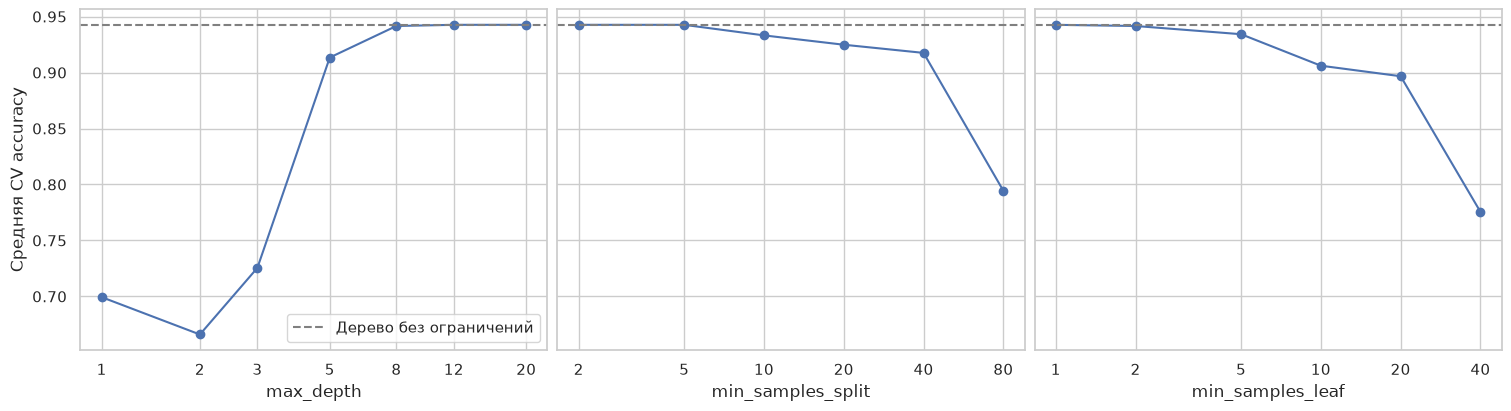

In [11]:
tic_tac_toe = pd.read_csv(DATA_DIR / "tic-tac-toe-endgame.csv")
X_tic_tac_toe = encode_columns(tic_tac_toe.iloc[:, :-1])
y_tic_tac_toe = LabelEncoder().fit_transform(tic_tac_toe.iloc[:, -1])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
accuracy = make_scorer(accuracy_score)


def validation_scores(model, X, y):
    return cross_val_score(model, X, y, cv=cv, scoring=accuracy, error_score="raise")


grids = {
    "max_depth": [1, 2, 3, 5, 8, 12, 20],
    "min_samples_split": [2, 5, 10, 20, 40, 80],
    "min_samples_leaf": [1, 2, 5, 10, 20, 40],
}
feature_types = ["categorical"] * X_tic_tac_toe.shape[1]
baseline_accuracy = validation_scores(DecisionTree(feature_types), X_tic_tac_toe, y_tic_tac_toe).mean()

rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout="constrained")
for ax, (param, values) in zip(axes, grids.items()):
    scores = []
    for value in values:
        model = DecisionTree(feature_types, **{param: value})
        scores.append(validation_scores(model, X_tic_tac_toe, y_tic_tac_toe).mean())
    best = int(np.argmax(scores))
    rows.append({"Параметр": param, "Лучшее значение в сетке": values[best], "CV accuracy": scores[best]})
    ax.plot(values, scores, marker="o")
    ax.axhline(baseline_accuracy, color="gray", linestyle="--", label="Дерево без ограничений")
    ax.set(xlabel=param, xscale="log", xticks=values, xticklabels=values)
    ax.minorticks_off()
axes[0].set_ylabel("Средняя CV accuracy")
axes[0].legend()
display(pd.DataFrame(rows).set_index("Параметр").round(4))
plt.show()

Лучший результат на каждой сетке совпал с accuracy дерева без ограничений
(`0,9426`). Для глубины эта точность достигнута при `max_depth=12`. У
минимального размера узла и листа максимум достигнут при стандартных
значениях `2` и `1`. Более сильное ограничение в этом эксперименте
снижало качество.

__Задание 9. (2 балла)__

Загрузите следующие наборы данных (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле *.names): 
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце)
* [tic-tac-toe](https://archive.ics.uci.edu/ml/datasets/Tic-Tac-Toe+Endgame) (классы записаны в последнем столбце, датасет лежит на гитхабе вместе с заданием)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав LabelEncoder. С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

Рекомендации:
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [12]:
uci = "https://archive.ics.uci.edu/ml/machine-learning-databases"
cars = pd.read_csv(f"{uci}/car/car.data", header=None)
nursery = pd.read_csv(f"{uci}/nursery/nursery.data", header=None)

cars_target = {"unacc": 0, "acc": 0, "good": 1, "vgood": 1}
nursery_target = {"not_recom": 0, "recommend": 0, "very_recom": 1, "priority": 1, "spec_prior": 1}

experiment_data = {
    "Mushrooms": (X_mushrooms, y_mushrooms),
    "Tic-tac-toe": (X_tic_tac_toe, y_tic_tac_toe),
    "Car Evaluation": (encode_columns(cars.iloc[:, :-1]), cars.iloc[:, -1].map(cars_target).to_numpy()),
    "Nursery": (encode_columns(nursery.iloc[:, :-1]), nursery.iloc[:, -1].map(nursery_target).to_numpy()),
}


def models_for(X):
    n_features = X.shape[1]
    n_indicators = sum(len(np.unique(column)) for column in X.T)
    categories = [np.unique(column) for column in X.T]
    return {
        "Своё · числовые коды": DecisionTree(["real"] * n_features),
        "Своё · категории": DecisionTree(["categorical"] * n_features),
        "Своё · one-hot": make_pipeline(
            OneHotEncoder(categories=categories, sparse_output=False, handle_unknown="ignore"),
            DecisionTree(["real"] * n_indicators),
        ),
        "sklearn · числовые коды": DecisionTreeClassifier(random_state=RANDOM_STATE),
    }


results = pd.DataFrame.from_dict({
    name: {method: validation_scores(model, X, y).mean() for method, model in models_for(X).items()}
    for name, (X, y) in experiment_data.items()
}, orient="index")
display(results.round(4))

,Своё · числовые коды,Своё · категории,Своё · one-hot,sklearn · числовые коды
Mushrooms,1.0000,1.0000,1.0000,1.0000
Tic-tac-toe,0.8789,0.9426,0.9384,0.8884
Car Evaluation,0.9919,0.9919,0.9884,0.9919
Nursery,0.9996,0.9998,0.9998,0.9997


__Задание 10. (1 балла)__

Проанализируйте результаты эксперимента. 
Одинаково ли для разных наборов данных ранжируются алгоритмы? 
Порассуждайте, почему так происходит. 

Обратите внимание на значение признаков в разных наборах данных. 
Присутствует ли в результатах какая-то компонента случайности? 
Можно ли повлиять на нее и улушить работу алгоритмов?

In [13]:
# Изменяем только номера категорий в каждой колонке tic-tac-toe.
rng = np.random.default_rng(RANDOM_STATE)
X, y = experiment_data["Tic-tac-toe"]
trials = [X]
for _ in range(5):
    trials.append(np.column_stack([
        rng.permutation(len(np.unique(column)))[column] for column in X.T
    ]))

encoding_scores = pd.DataFrame([
    {name: validation_scores(model, encoded, y).mean()
     for name, model in models_for(encoded).items()}
    for encoded in trials
], index=["Исходное кодирование", *[f"Перестановка {i}" for i in range(1, len(trials))]])
display(encoding_scores.round(4))

,Своё · числовые коды,Своё · категории,Своё · one-hot,sklearn · числовые коды
Исходное кодирование,0.8789,0.9426,0.9384,0.8884
Перестановка 1,0.9447,0.9426,0.9436,0.9395
Перестановка 2,0.9384,0.9426,0.9426,0.9405
Перестановка 3,0.9343,0.9426,0.9416,0.9343
Перестановка 4,0.9291,0.9426,0.9478,0.9238
Перестановка 5,0.9196,0.9426,0.9468,0.9134


**Ответ:**

- **Mushrooms.** Все четыре модели получили среднюю accuracy `1,0000`.
  Для этой выборки информации в признаках хватает при каждом кодировании.
- **Tic-tac-toe.** Лидирует категориальное дерево с `0,9426`, рядом
  one-hot с `0,9384`. Буквы `x`, `o` и `b` обозначают крестик, нолик и
  пустую клетку. У них нет естественного порядка. Числовой порог может
  отделить крайний код одним разбиением, а для среднего кода обычно нужны
  два. Категориальное дерево может сразу проверить подходящее множество
  значений, а one-hot позволяет отдельно проверить каждое значение.
- **Car Evaluation.** Оба дерева на числовых кодах и категориальное
  дерево дали `0,9919`, one-hot — `0,9884`. У уровня безопасности,
  вместимости и цены есть содержательный порядок. Порог по правильно
  упорядоченным уровням может объединить несколько уровней одним
  разбиением. Порядок `LabelEncoder` алфавитный, поэтому для порядковых
  признаков имеет смысл проверять явное кодирование по смыслу.
- **Nursery.** Accuracy всех вариантов находится между `0,9996` и
  `0,9998`. В этих фолдах выбор кодирования почти не повлиял на результат.

На тех же фолдах tic-tac-toe пять перестановок кодов изменили accuracy
числового дерева с `0,8789` до значений в диапазоне `0,9196–0,9447`.
Категориальное дерево во всех шести запусках сохранило `0,9426`. У one-hot
диапазон составил `0,9384–0,9478`. Перестановка индикаторов меняет порядок
перебора признаков, поэтому при одинаковых значениях Джини дерево может
выбрать другой сплит. Влияние оказывают также состав фолдов и разрешение
ничьих в `sklearn`, поэтому для сравнений зафиксированы разбиения и
`random_state`. Для устойчивой оценки можно повторить стратифицированную
кросс-валидацию с несколькими seed. Чтобы проверить улучшение, способ
кодирования и ограничения дерева следует выбирать на обучающих данных и
оценивать на отдельном тесте.

Вставьте что угодно, описывающее ваши впечатления от этого задания:

Самым наглядным оказался эксперимент с tic-tac-toe. Значения в клетках
остались теми же, а одной перестановки их числовых кодов хватило, чтобы
заметно изменить качество дерева.